In [1]:
import pandas as pd 

df = pd.read_csv('data/supermarket.csv')
df

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,1/5/2019,13:08,Ewallet,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3/8/2019,10:29,Cash,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,3/3/2019,13:23,Credit card,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,1/27/2019,20:33,Ewallet,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2/8/2019,10:37,Ewallet,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,1/29/2019,13:46,Ewallet,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,3/2/2019,17:16,Ewallet,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,2/9/2019,13:22,Cash,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,2/22/2019,15:33,Cash,4.1


In [2]:
# Mengonversi kolom 'Date' menjadi tipe datetime
df['Date'] = pd.to_datetime(df['Date'])

# Menambahkan fitur 'Total Sales' (Unit price * Quantity)
df['Total Sales'] = df['Unit price'] * df['Quantity']

In [3]:
# Menambahkan fitur hari ke depan (misalnya 1 hari setelah transaksi)
df['Next Day'] = df['Date'] + pd.Timedelta(days=1)

# Menampilkan data dengan kolom baru
print(df[['Date', 'Next Day', 'Unit price', 'Quantity', 'Total Sales']].head())


        Date   Next Day  Unit price  Quantity  Total Sales
0 2019-01-05 2019-01-06       74.69         7       522.83
1 2019-03-08 2019-03-09       15.28         5        76.40
2 2019-03-03 2019-03-04       46.33         7       324.31
3 2019-01-27 2019-01-28       58.22         8       465.76
4 2019-02-08 2019-02-09       86.31         7       604.17


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Mengonversi tanggal ke format numerik untuk digunakan dalam model
df['Date_ordinal'] = df['Date'].apply(lambda x: x.toordinal())

# Memilih fitur yang relevan untuk model
X = df[['Unit price', 'Quantity', 'Date_ordinal']]
y = df['Total Sales']

# Membagi data menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [5]:
# Menginisialisasi model regresi linear
model = LinearRegression()

# Melatih model dengan data pelatihan
model.fit(X_train, y_train)


LinearRegression()

In [6]:
# Menyiapkan data untuk tanggal selanjutnya
future_data = pd.DataFrame({
    'Unit price': [74.69, 15.28, 46.33],  # Harga per unit berdasarkan data contoh
    'Quantity': [7, 5, 7],                # Kuantitas berdasarkan data contoh
    'Date_ordinal': [(df['Date'].max() + pd.Timedelta(days=1)).toordinal()] * 3
})

# Melakukan prediksi untuk tanggal selanjutnya
future_sales_pred = model.predict(future_data)

# Menampilkan hasil prediksi
future_data['Predicted Sales'] = future_sales_pred
print(future_data)


   Unit price  Quantity  Date_ordinal  Predicted Sales
0       74.69         7        737149       493.133564
1       15.28         5        737149        54.163289
2       46.33         7        737149       336.538714


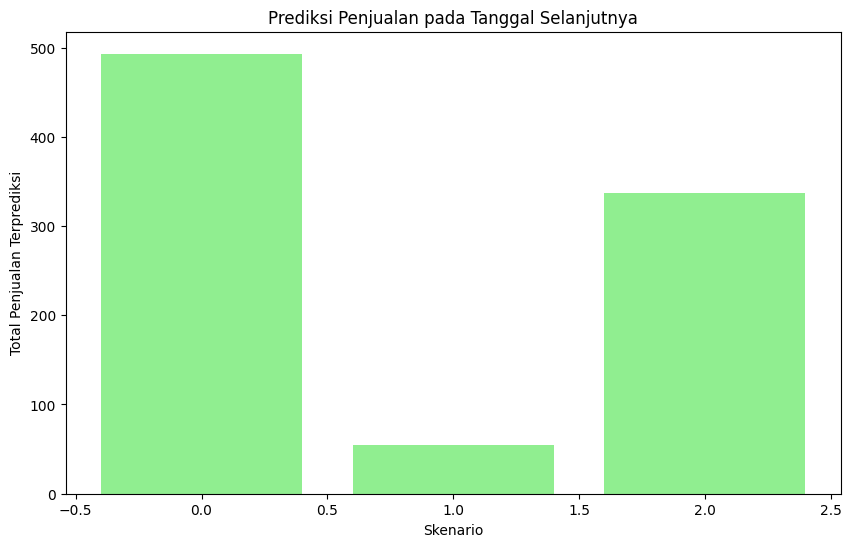

In [7]:
import matplotlib.pyplot as plt

# Visualisasi prediksi penjualan pada tanggal selanjutnya
plt.figure(figsize=(10, 6))
plt.bar(future_data.index, future_data['Predicted Sales'], color='lightgreen')
plt.title('Prediksi Penjualan pada Tanggal Selanjutnya')
plt.xlabel('Skenario')
plt.ylabel('Total Penjualan Terprediksi')
plt.show()


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.stattools import adfuller

# 1. Pengumpulan Data
data = pd.read_csv('data_time_series.csv', parse_dates=['Date'], index_col='Date')

# 2. Pra-pemrosesan Data
plt.figure(figsize=(10, 6))
plt.plot(data)
plt.title('Time Series Data')
plt.show()

# Uji Stasionaritas
result = adfuller(data['Value'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])

# Jika p-value > 0.05, data tidak stasioner, lakukan diferensiasi
data_diff = data.diff().dropna()

# 3. Identifikasi Model
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(data_diff)
plot_pacf(data_diff)
plt.show()

# 4. Estimasi Model
model = ARIMA(data, order=(p, d, q))
model_fit = model.fit(disp=0)

# 5. Evaluasi Model
print(model_fit.summary())

# 6. Prediksi
forecast = model_fit.forecast(steps=10)
forecast_df = pd.DataFrame(forecast[0], index=pd.date_range(start=data.index[-1], periods=11, closed='right'), columns=['Forecast'])

plt.figure(figsize=(10, 6))
plt.plot(data, label='Actual Data')
plt.plot(forecast_df, label='Forecast', color='red')
plt.title('Forecast vs Actual Data')
plt.legend()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'data_time_series.csv'